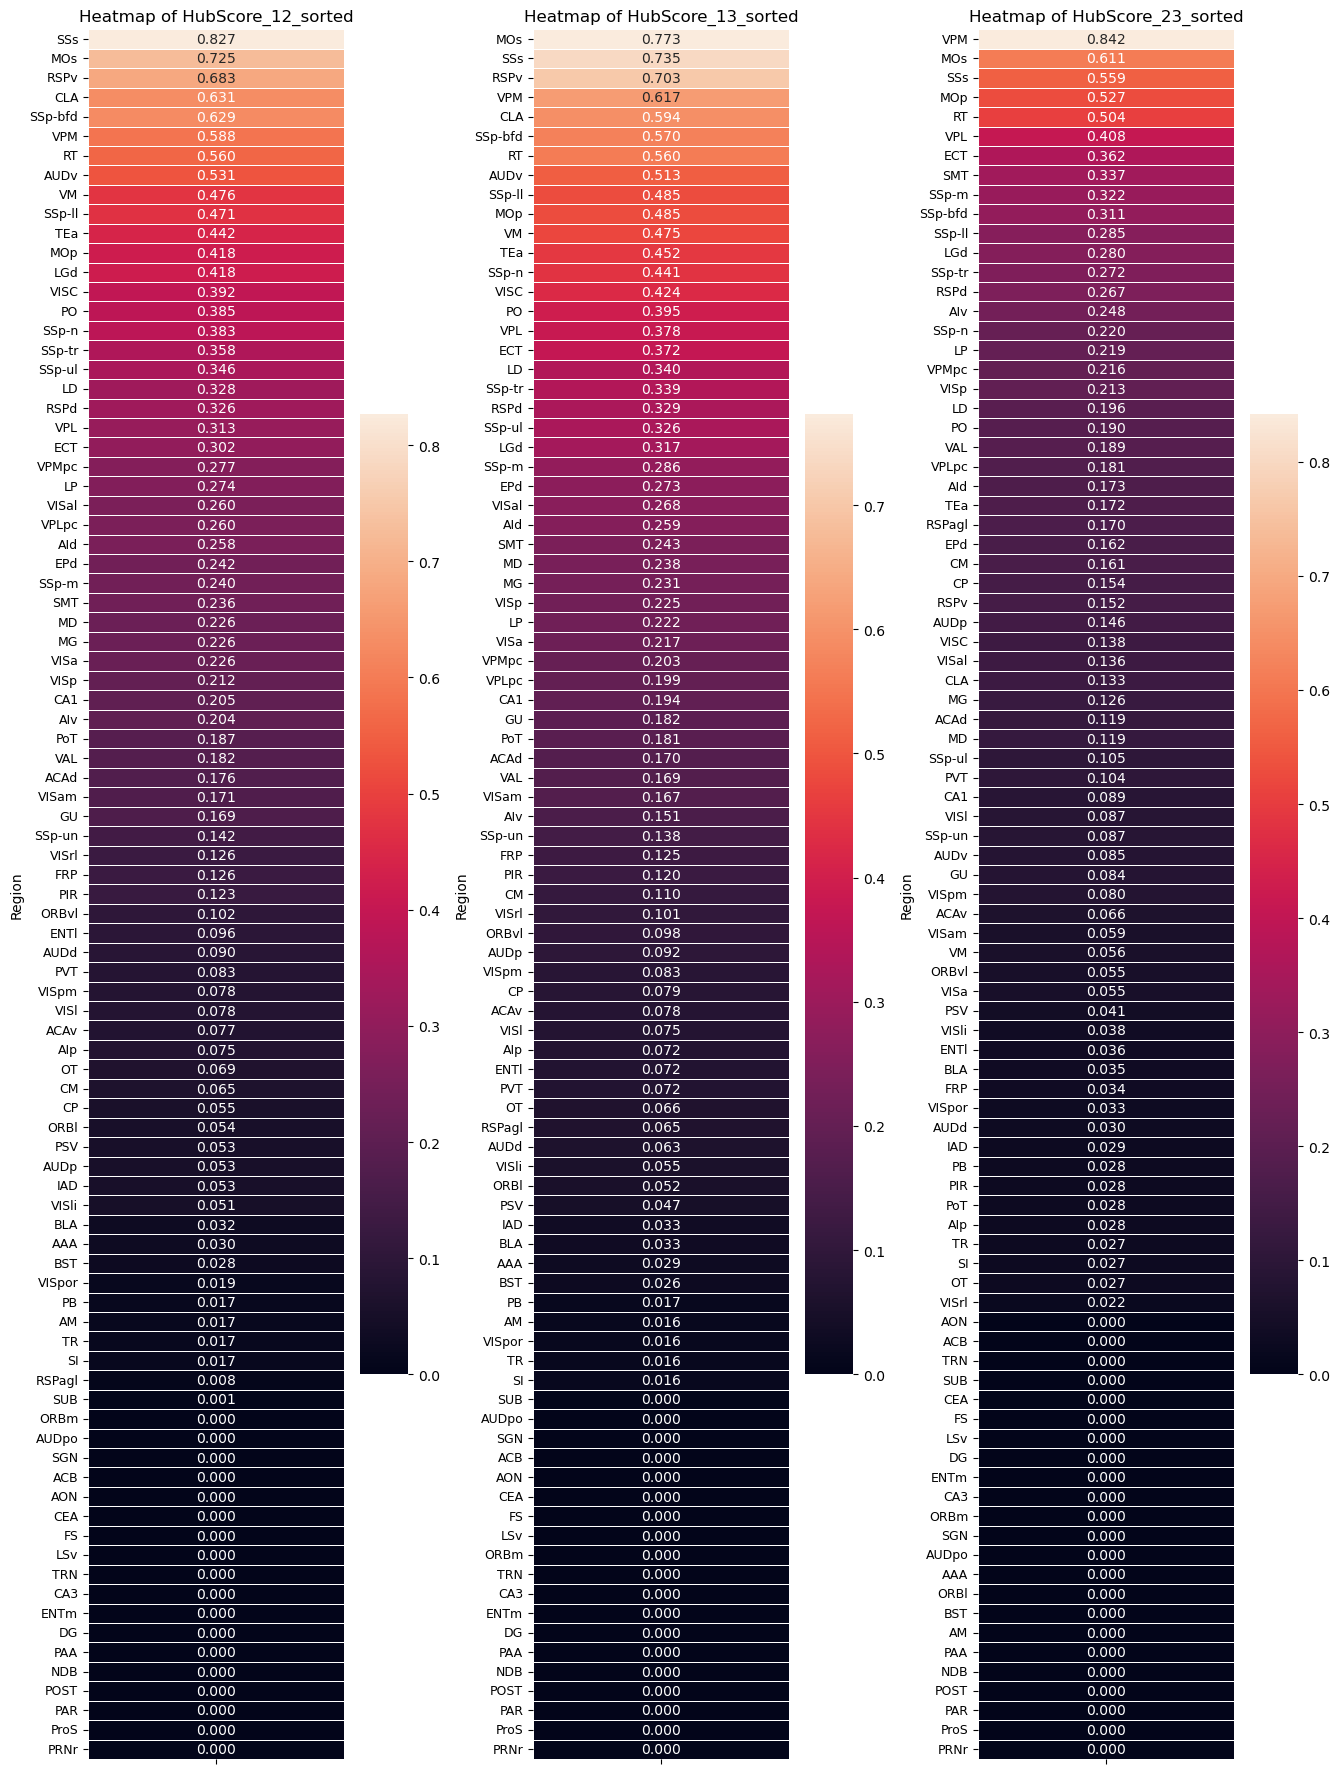

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import os

files = [
    "HubScore_12_sorted.csv",
    "HubScore_13_sorted.csv",
    "HubScore_23_sorted.csv"
]

valid_dfs = []
titles = []

for file in files:
    if not os.path.exists(file):
        continue
    df = pd.read_csv(file, header=None, skiprows=1, names=["Region", "Value"])
    df["Value"] = pd.to_numeric(df["Value"], errors="coerce")
    df = df.dropna(subset=["Value"])
    valid_dfs.append(df.set_index("Region")[["Value"]])
    titles.append(file.replace(".csv", ""))

if not valid_dfs:
    raise FileNotFoundError("None of the specified CSV files exist in the current directory.")

n_plots = len(valid_dfs)
fig, axes = plt.subplots(1, n_plots, figsize=(4.5 * n_plots, 0.2 * max(len(df) for df in valid_dfs)))
if n_plots == 1:
    axes = [axes]

for ax, data, title in zip(axes, valid_dfs, titles):
    sns.heatmap(
        data,
        annot=True,
        fmt=".3f",
        cmap="rocket",
        cbar=True,
        linewidths=0.5,
        square=False,
        ax=ax
    )
    ax.set_title(f"Heatmap of {title}", fontsize=12)
    ax.set_yticklabels(ax.get_yticklabels(), rotation=0, fontsize=9)
    ax.set_xticklabels([])

plt.tight_layout()
plt.savefig("Combined_HubScore_Heatmaps.png", dpi=300, bbox_inches="tight")
plt.show()